# Experiment 15: final interaction-layer transfer

Best-checkpoint evaluation on the same 50 validation structures (2,400 Si and 4,800 O atoms) used for experiments 13A, 13B and 14. Targets are absolute DFT isotropic shieldings in ppm. RMSE, MAE and R² are pooled over atoms within each element. No training or test labels are read.

The shared readout and fourth interaction layer train from the original E/F backbone; embeddings and the first three layers remain frozen. Initial AdamW learning rate: 0.003. Comparison values for 13A/B/14 come from the previously executed validation evaluation. This notebook reruns all 50 experiment-15 forward passes when executed.

## Results and interpretation

- **Si:** RMSE **1.251 ppm**, MAE **0.681 ppm**, R² **0.981**.
- **O:** RMSE **2.797 ppm**, MAE **1.548 ppm**, R² **0.982**.

Best checkpoint: epoch **283**; last checkpoint: epoch **583**, with **300** validation checks since the best. The saved summary reports 300 checks without improvement and the run log reports training complete, consistent with validation early stopping rather than a timeout.

The transfer checks confirm that embeddings and the first three interaction layers match the E/F source exactly, while the fourth layer changed. The exported model matches best.ckpt, and the recomputed validation objective matches the saved best score. The final epoch's W&B summary metrics are not the best-checkpoint metrics plotted here.

These are validation results on the split used for checkpoint selection, not independent test performance. Comparisons assess observed performance across the experiments; head arrangement and training history differ as well as the trainable layers.

Relative to experiment 14, RMSE decreases by **55.5% for Si** and **56.7% for O**. Both parity plots are much tighter around the diagonal, although scattered outliers remain, particularly for low oxygen shieldings. The <1 ppm Si and <2 ppm O targets are met in MAE but not yet in RMSE.

The CPU-recomputed objective differs from the saved GPU value by approximately 0.032%, within the stated 0.05% numerical tolerance.

## Load best checkpoint and verify transfer

In [1]:
from pathlib import Path
import os, sys, json, hashlib
import numpy as np
import pandas as pd
import torch, yaml
from ase.io import read
from graph_pes.atomic_graph import AtomicGraph
from IPython.display import display, Image
import matplotlib.pyplot as plt
ROOT = Path('/Users/louismcauliffe/code/research/NequIP_experiments')
sys.path.insert(0, str(ROOT))
import nmr_helpers
NAME = '15-TensorNequIP-NMR-LastLayer-9148082'
RUN = ROOT/'graph-pes-results'/NAME
OUT = Path(globals().get('ARTIFACT_DIR', ROOT/'experiments'/(NAME+'-figures')))
OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(4)
torch.set_default_dtype(torch.float32)
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
paths = [RUN/'model.pt', RUN/'checkpoints/best.ckpt', RUN/'checkpoints/last.ckpt',
         RUN/'train-config.yaml', RUN/'summary.yaml', ROOT/'data/nmr_iso/valid.xyz',
         ROOT/'graph-pes-results/Kavanagh-Med-9059603/model.pt']
hashes = {str(p):sha(p) for p in paths}
config = yaml.safe_load((RUN/'train-config.yaml').read_text())
assert config['data']['valid']['path'] == 'data/nmr_iso/valid.xyz'
model = torch.load(RUN/'model.pt', map_location='cpu', weights_only=False)
best = torch.load(RUN/'checkpoints/best.ckpt', map_location='cpu', weights_only=False)
last = torch.load(RUN/'checkpoints/last.ckpt', map_location='cpu', weights_only=False)
weights = {k.removeprefix('model.'):v for k,v in best['state_dict'].items() if k.startswith('model.')}
def equal(a,b):
    if torch.is_tensor(a): return torch.equal(a,b)
    if isinstance(a,dict): return a.keys()==b.keys() and all(equal(a[k],b[k]) for k in a)
    if isinstance(a,(list,tuple)): return len(a)==len(b) and all(equal(x,y) for x,y in zip(a,b))
    return a==b
assert equal(model.state_dict(),weights), 'Export does not match best checkpoint'
model.load_state_dict(weights,strict=True)
model.eval().requires_grad_(False)
source = torch.load(paths[-1],map_location='cpu',weights_only=False).models['nequip']
nq = model.models['nequip']
for part in ['Z_embedding','initial_node_embedding','edge_embedding']:
    assert equal(getattr(nq,part).state_dict(),getattr(source,part).state_dict())
assert all(equal(nq.layers[i].state_dict(),source.layers[i].state_dict()) for i in range(3))
assert not equal(nq.layers[3].state_dict(),source.layers[3].state_dict())
assert nq.tensor_readout.weight.numel()==128
early = next(v for k,v in last['callbacks'].items() if k.startswith('EarlyStopping'))
provenance = dict(best_epoch=int(best['epoch'])+1,last_epoch=int(last['epoch'])+1,
    checks_since_best=early['total_checks']-early['best_val_loss_check'],
    saved_best_loss=early['best_val_loss'], initial_lr=config['fitting']['optimizer']['lr'],
    frozen_embeddings_and_first_three_layers_verified=True,final_layer_changed=True,
    export_matches_best=True)
display(pd.DataFrame([provenance]))

,best_epoch,last_epoch,checks_since_best,saved_best_loss,initial_lr,frozen_embeddings_and_first_three_layers_verified,final_layer_changed,export_matches_best
0,283,583,300,0.020748,0.003,True,True,True


## Validation predictions and elemental metrics

In [2]:
frames = read(ROOT/'data/nmr_iso/valid.xyz',index=':')
assert len(frames)==50
records=[]
with torch.inference_mode():
    for index,atoms in enumerate(frames):
        graph=AtomicGraph.from_ase(atoms,cutoff=6.0)
        assert not graph.properties  # Labels are not supplied to the model.
        y=np.asarray(atoms.arrays['MS_Iso_QM'],dtype=np.float64)
        p=model.predict(graph,['tensor'])['tensor'].cpu().numpy().astype(np.float64)
        assert y.shape==p.shape==(len(atoms),) and np.isfinite(p).all()
        records.append(pd.DataFrame(dict(structure=index,atom=np.arange(len(atoms)),
            element=atoms.get_chemical_symbols(),reference=y,prediction=p)))
        if (index+1)%10==0: print(f'Evaluated {index+1}/50 validation structures',flush=True)
sites=pd.concat(records,ignore_index=True)
rows=[]
for element,g in sites.groupby('element'):
    y,p=g.reference.to_numpy(),g.prediction.to_numpy()
    rows.append(dict(run='15',checkpoint='best',element=element,N=len(g),
        RMSE=float(np.sqrt(np.mean((p-y)**2))),MAE=float(np.mean(abs(p-y))),
        R2=float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2))))
metrics=pd.DataFrame(rows)
m=metrics.set_index('element')
assert m.loc['Si','N']==2400 and m.loc['O','N']==4800
loss=config['loss']['isotropy']['+nmr_helpers.shared_head_training.ElementBalancedMSE']
objective=loss['weight']*.5*(m.loc['Si','RMSE']**2/loss['si_std']**2+m.loc['O','RMSE']**2/loss['o_std']**2)
assert np.isclose(objective,provenance['saved_best_loss'],rtol=5e-4)
display(metrics.round(5))
print(f'Recomputed validation objective: {objective:.8f}; saved: {provenance["saved_best_loss"]:.8f}')

Evaluated 10/50 validation structures
Evaluated 20/50 validation structures
Evaluated 30/50 validation structures
Evaluated 40/50 validation structures
Evaluated 50/50 validation structures
Recomputed validation objective: 0.02074168; saved: 0.02074831


,run,checkpoint,element,N,RMSE,MAE,R2
0,15,best,O,4800,2.79668,1.54783,0.98218
1,15,best,Si,2400,1.25113,0.68054,0.98094


## Parity plots and comparison with frozen-backbone experiments

Si: RMSE reduction versus 14 = 55.5%
O: RMSE reduction versus 14 = 56.7%
Out[0]: 2065


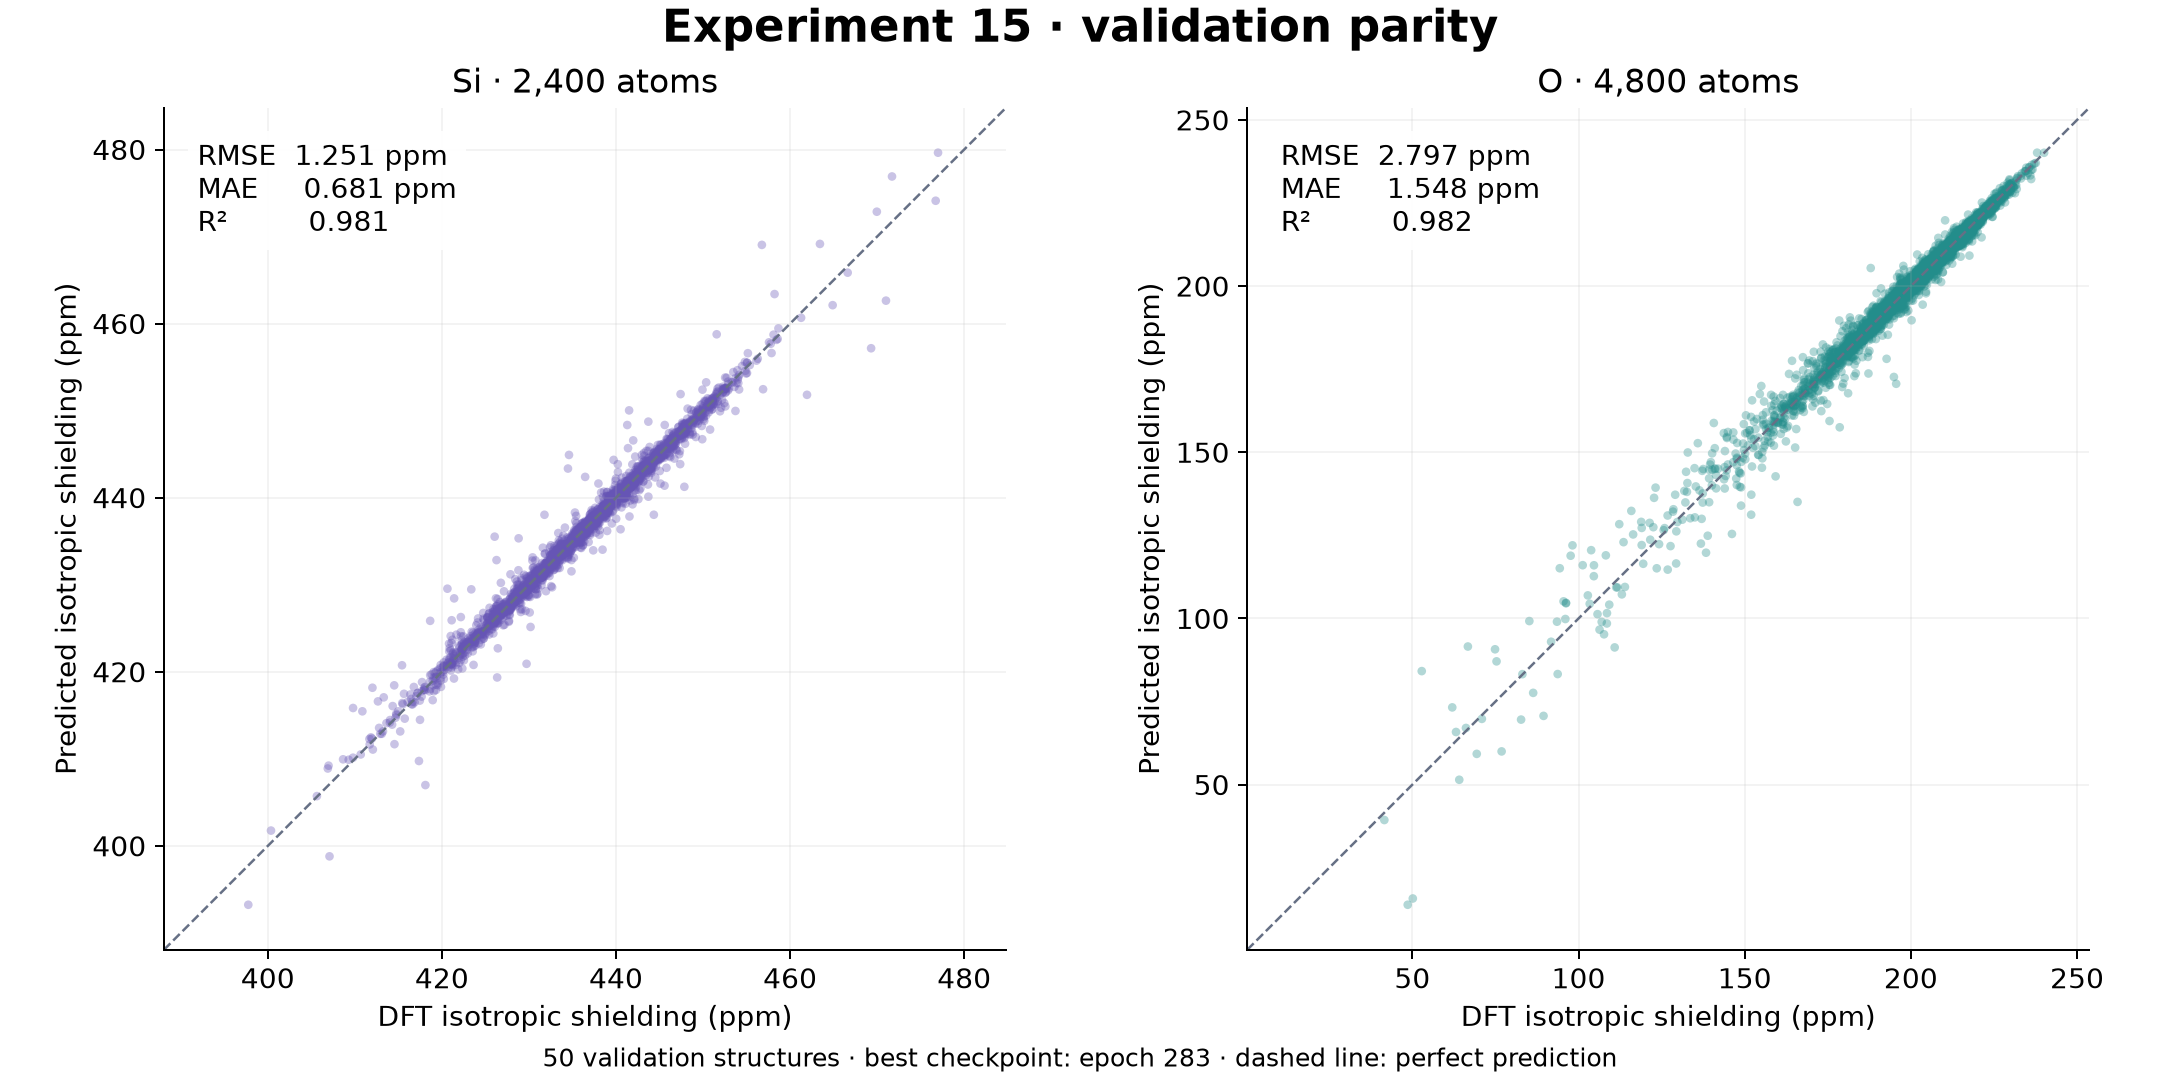

,run,element,RMSE,MAE,R2
0,13A,O,6.7212,4.2887,0.8971
1,13A,Si,4.2013,3.0271,0.7851
2,13B,O,7.8415,4.9548,0.8599
3,13B,Si,3.2241,2.2715,0.8734
4,14,O,6.4648,4.0862,0.9048
5,14,Si,2.8117,1.9635,0.9038
6,15,O,2.7967,1.5478,0.9822
7,15,Si,1.2511,0.6805,0.9809


In [3]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,
    'axes.spines.right':False,'savefig.facecolor':'white'})
def panel(ax,element):
    g=sites.query('element==@element'); row=m.loc[element]
    lo=min(g.reference.min(),g.prediction.min()); hi=max(g.reference.max(),g.prediction.max())
    pad=.06*(hi-lo); limits=(lo-pad,hi+pad)
    ax.scatter(g.reference,g.prediction,s=12,alpha=.35,color={'Si':'#6655B5','O':'#238D8B'}[element],edgecolors='none',rasterized=True)
    ax.plot(limits,limits,'--',color='#667085',linewidth=1)
    ax.set(xlim=limits,ylim=limits,aspect='equal',title=f'{element} · {int(row.N):,} atoms',
        xlabel='DFT isotropic shielding (ppm)',ylabel='Predicted isotropic shielding (ppm)')
    ax.text(.04,.96,f'RMSE  {row.RMSE:.3f} ppm\nMAE     {row.MAE:.3f} ppm\nR²         {row.R2:.3f}',
        transform=ax.transAxes,va='top',bbox=dict(facecolor='white',alpha=.95,edgecolor='none'))
    ax.grid(alpha=.15)
fig,axes=plt.subplots(1,2,figsize=(12,6),layout='constrained')
for ax,element in zip(axes,['Si','O']): panel(ax,element)
fig.suptitle('Experiment 15 · validation parity',fontsize=18,weight='bold')
fig.supxlabel(f'50 validation structures · best checkpoint: epoch {provenance["best_epoch"]:,} · dashed line: perfect prediction',fontsize=10)
for ext in ['png','pdf']: fig.savefig(OUT/f'validation-parity.{ext}',dpi=180)
plt.close(fig)
display(Image(filename=str(OUT/'validation-parity.png')))
for element in ['Si','O']:
    fig,ax=plt.subplots(figsize=(6,6),layout='constrained'); panel(ax,element)
    fig.suptitle('Experiment 15 · validation parity')
    for ext in ['png','pdf']: fig.savefig(OUT/f'parity-{element}.{ext}',dpi=180)
    plt.close(fig)
previous=ROOT/'experiments/14-TensorNequIP-NMR-SeparateHeads-9136987-figures'
manifest=json.loads((previous/'manifest.json').read_text())
assert manifest['files_sha256'][str(ROOT/'data/nmr_iso/valid.xyz')]==hashes[str(ROOT/'data/nmr_iso/valid.xyz')]
old=pd.read_csv(previous/'metrics.csv',dtype={'run':str}).query('checkpoint=="best"')
comparison=pd.concat([old[metrics.columns],metrics],ignore_index=True)
display(comparison[['run','element','RMSE','MAE','R2']].round(4))
for element in ['Si','O']:
    baseline=old.query('run=="14" and element==@element').iloc[0]
    print(f'{element}: RMSE reduction versus 14 = {100*(1-m.loc[element,"RMSE"]/baseline.RMSE):.1f}%')
metrics.to_csv(OUT/'metrics.csv',index=False)
comparison.to_csv(OUT/'comparison.csv',index=False)
sites.to_csv(OUT/'predictions.csv.gz',index=False)
assert all(sha(p)==v for p,v in hashes.items())
(OUT/'manifest.json').write_text(json.dumps(dict(input_sha256=hashes,provenance=provenance,
    evaluated_split='validation',structures=50,recomputed_best_loss=objective,
    training_or_test_labels_read=False,comparison_source=str(previous/'metrics.csv'),
    comparison_source_sha256=sha(previous/'metrics.csv')),indent=2))

## Side-by-side parity: experiments 14 and 15

Best-checkpoint predictions on identical validation sites. Axes match across experiments within each elemental row; no predictions are recomputed.

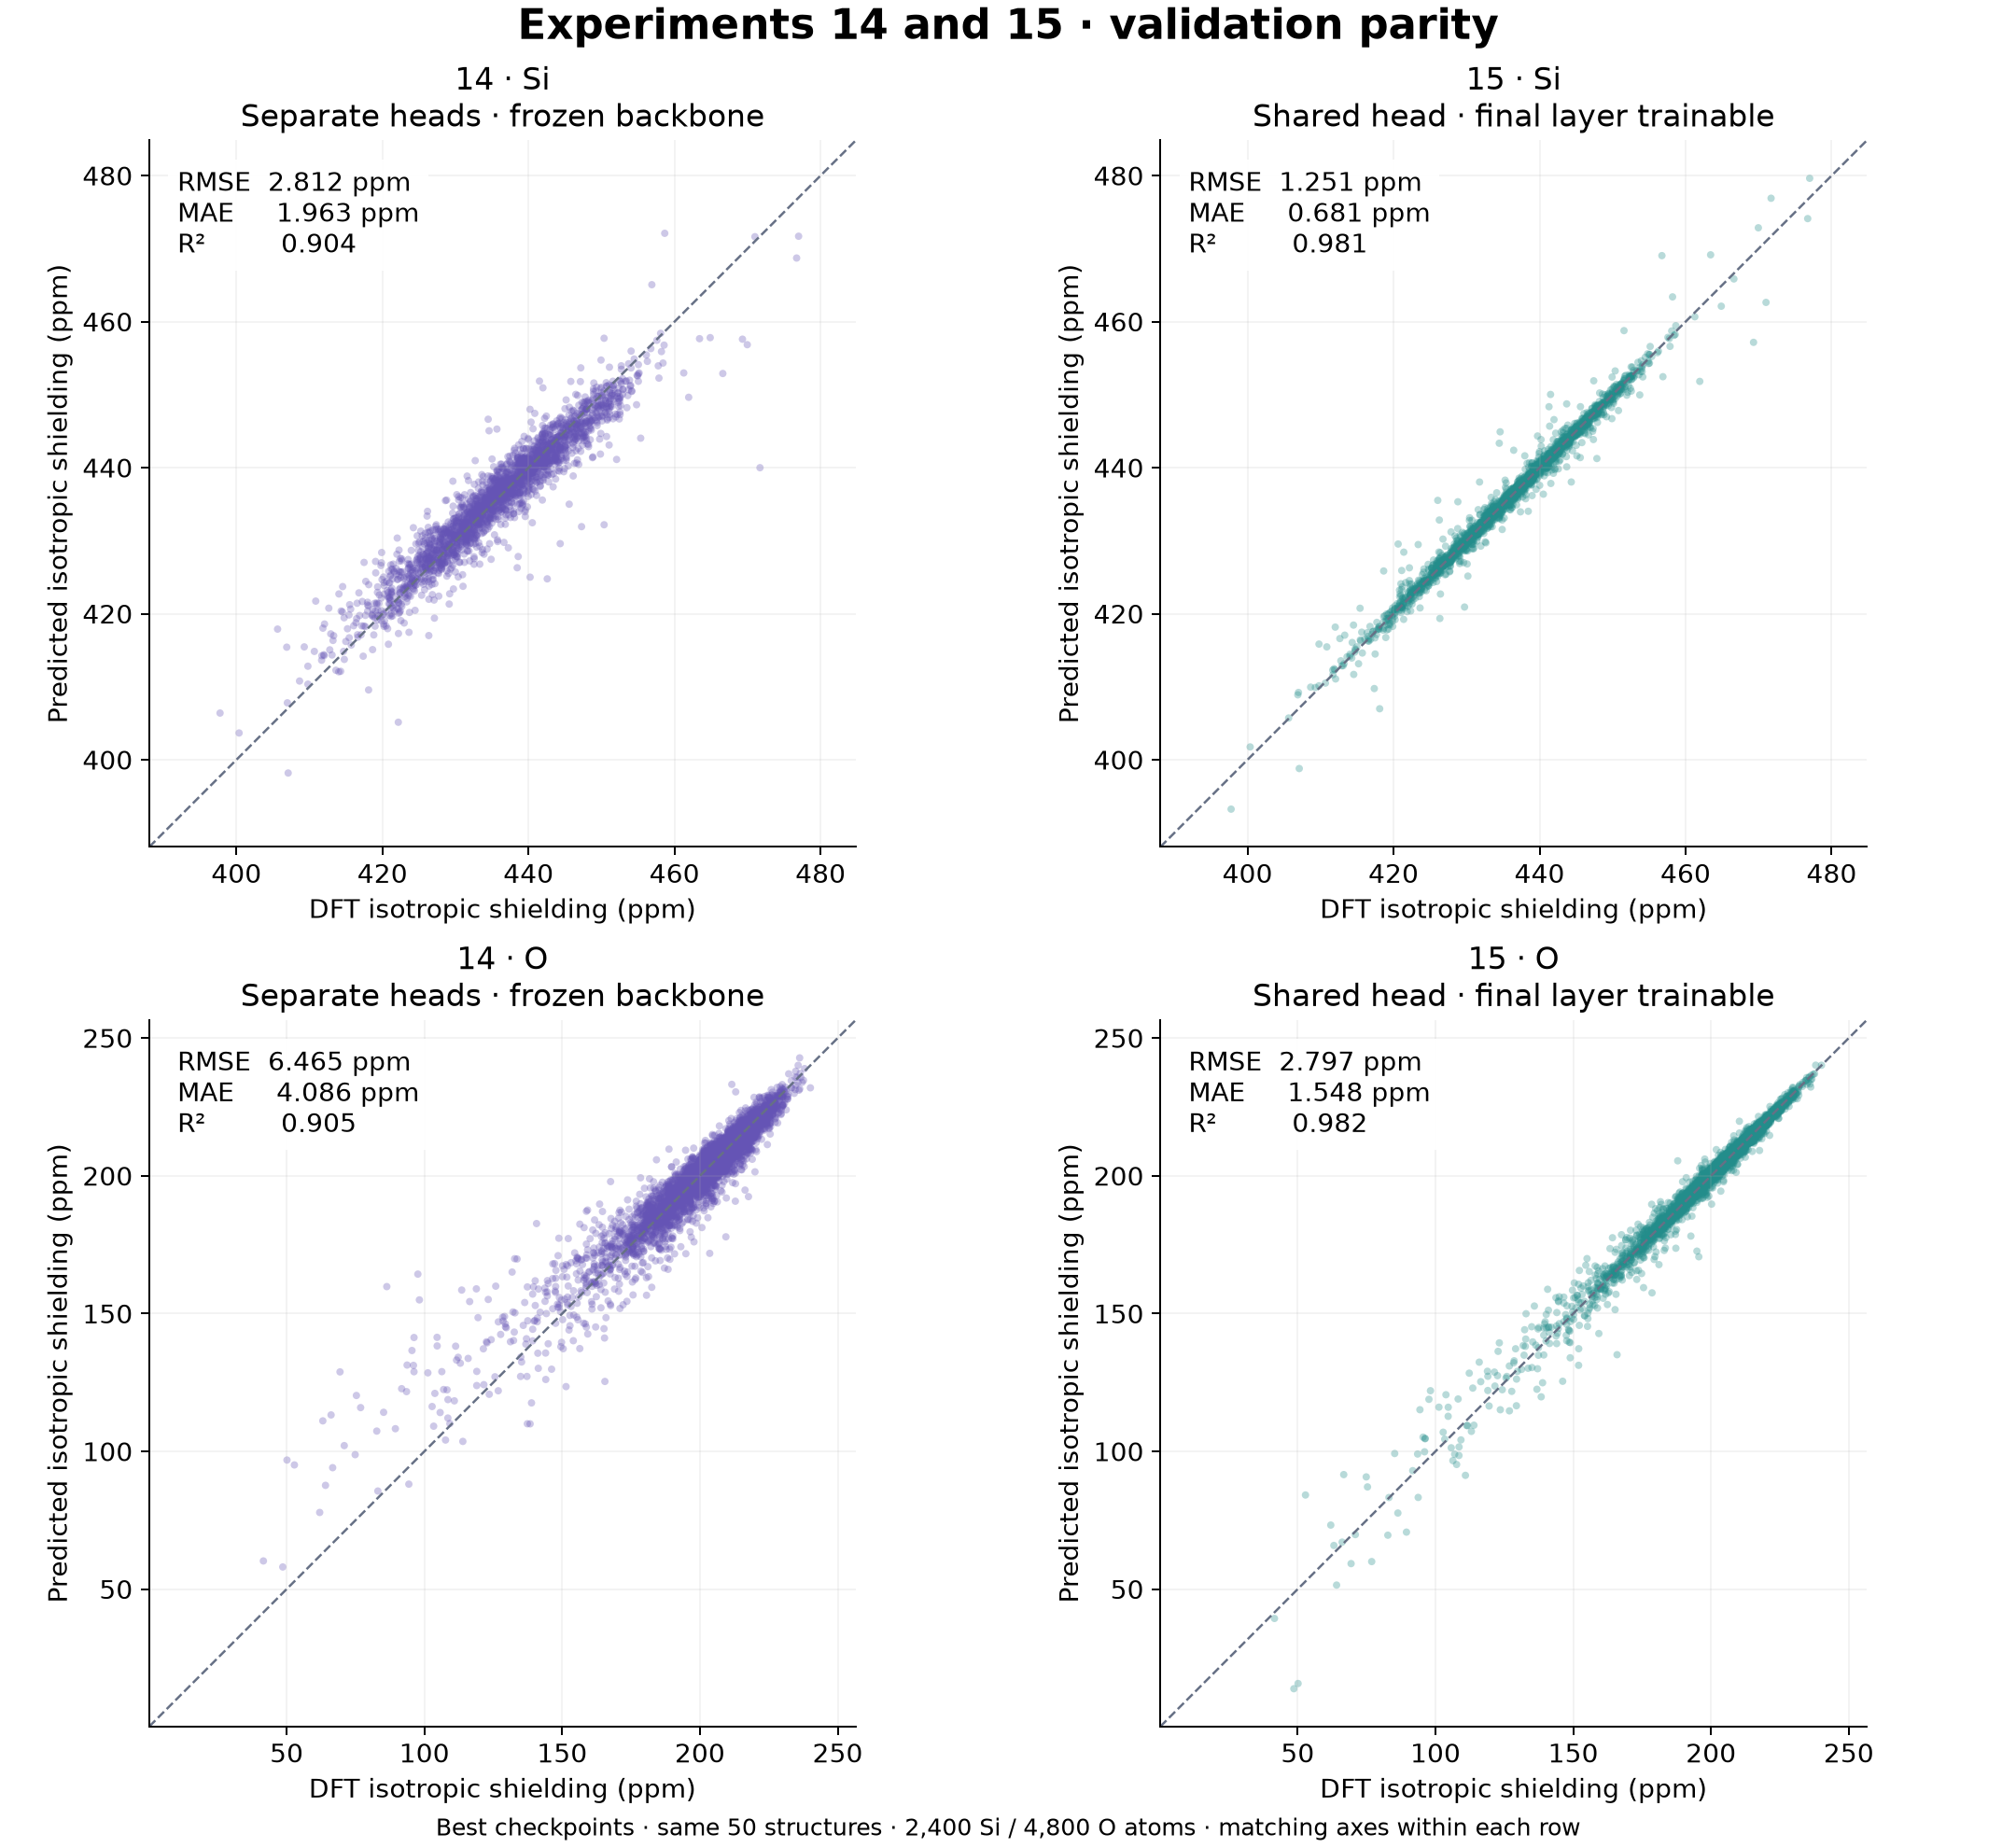

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

comparison_root = Path('/Users/louismcauliffe/code/research/NequIP_experiments/experiments')
comparison_name = '15-TensorNequIP-NMR-LastLayer-9148082'
comparison_out = Path(globals().get('COMPARISON_OUTPUT_DIR', comparison_root/(comparison_name+'-figures')))
comparison_out.mkdir(parents=True, exist_ok=True)
prior = pd.read_csv(comparison_root/'14-TensorNequIP-NMR-SeparateHeads-9136987-figures/predictions.csv.gz', dtype={'run':str})
prior = prior.query('run == "14" and checkpoint == "best"').copy()
current = pd.read_csv(comparison_root/(comparison_name+'-figures')/'predictions.csv.gz')
current['run'] = '15'
# Check that both runs predict exactly the same reference sites.
keys = ['structure','atom','element']
a = prior.sort_values(keys).reset_index(drop=True)
b = current.sort_values(keys).reset_index(drop=True)
assert a[keys].equals(b[keys])
assert np.allclose(a.reference, b.reference, rtol=0, atol=1e-9)
combined = pd.concat([prior, current], ignore_index=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,
    'axes.spines.top':False,'axes.spines.right':False,'savefig.facecolor':'white'})
fig, axes = plt.subplots(2,2,figsize=(12,11),layout='constrained')
for row, element in enumerate(['Si','O']):
    all_sites = combined.query('element == @element')
    lo = min(all_sites.reference.min(), all_sites.prediction.min())
    hi = max(all_sites.reference.max(), all_sites.prediction.max())
    pad = .06*(hi-lo)
    limits = (lo-pad, hi+pad)
    for col, run in enumerate(['14','15']):
        ax = axes[row,col]
        g = all_sites.query('run == @run')
        y, p = g.reference.to_numpy(), g.prediction.to_numpy()
        rmse = np.sqrt(np.mean((p-y)**2))
        mae = np.mean(abs(p-y))
        r2 = 1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)
        ax.scatter(y,p,s=10,alpha=.32,edgecolors='none',rasterized=True,
            color={'14':'#6554B5','15':'#238D8B'}[run])
        ax.plot(limits,limits,'--',color='#667085',linewidth=1)
        description = {'14':'Separate heads · frozen backbone','15':'Shared head · final layer trainable'}[run]
        ax.set(xlim=limits,ylim=limits,aspect='equal',title=f'{run} · {element}\n{description}',
            xlabel='DFT isotropic shielding (ppm)',ylabel='Predicted isotropic shielding (ppm)')
        ax.text(.04,.96,f'RMSE  {rmse:.3f} ppm\nMAE     {mae:.3f} ppm\nR²         {r2:.3f}',
            transform=ax.transAxes,va='top',bbox=dict(facecolor='white',alpha=.95,edgecolor='none'))
        ax.grid(alpha=.15)
fig.suptitle('Experiments 14 and 15 · validation parity',fontsize=18,weight='bold')
fig.supxlabel('Best checkpoints · same 50 structures · 2,400 Si / 4,800 O atoms · matching axes within each row',fontsize=10)
for ext in ['png','pdf']:
    fig.savefig(comparison_out/f'validation-parity-14-vs-15.{ext}',dpi=180)
plt.close(fig)
display(Image(filename=str(comparison_out/'validation-parity-14-vs-15.png')))


## Direct NMR versus transfer: experiments 08, 14 and 15

Best checkpoints on the same 50 validation structures, with matching axes and unweighted RMSE, MAE and R² for each element. Experiment 08 trains directly on NMR with 3× coordination-defect weighting; 14 uses frozen-backbone separate heads; 15 trains a shared head and final interaction layer. This compares these fitted models, rather than isolating architecture from the different training losses. Predictions for 08 are recomputed; 14 and 15 reuse their saved validation predictions.

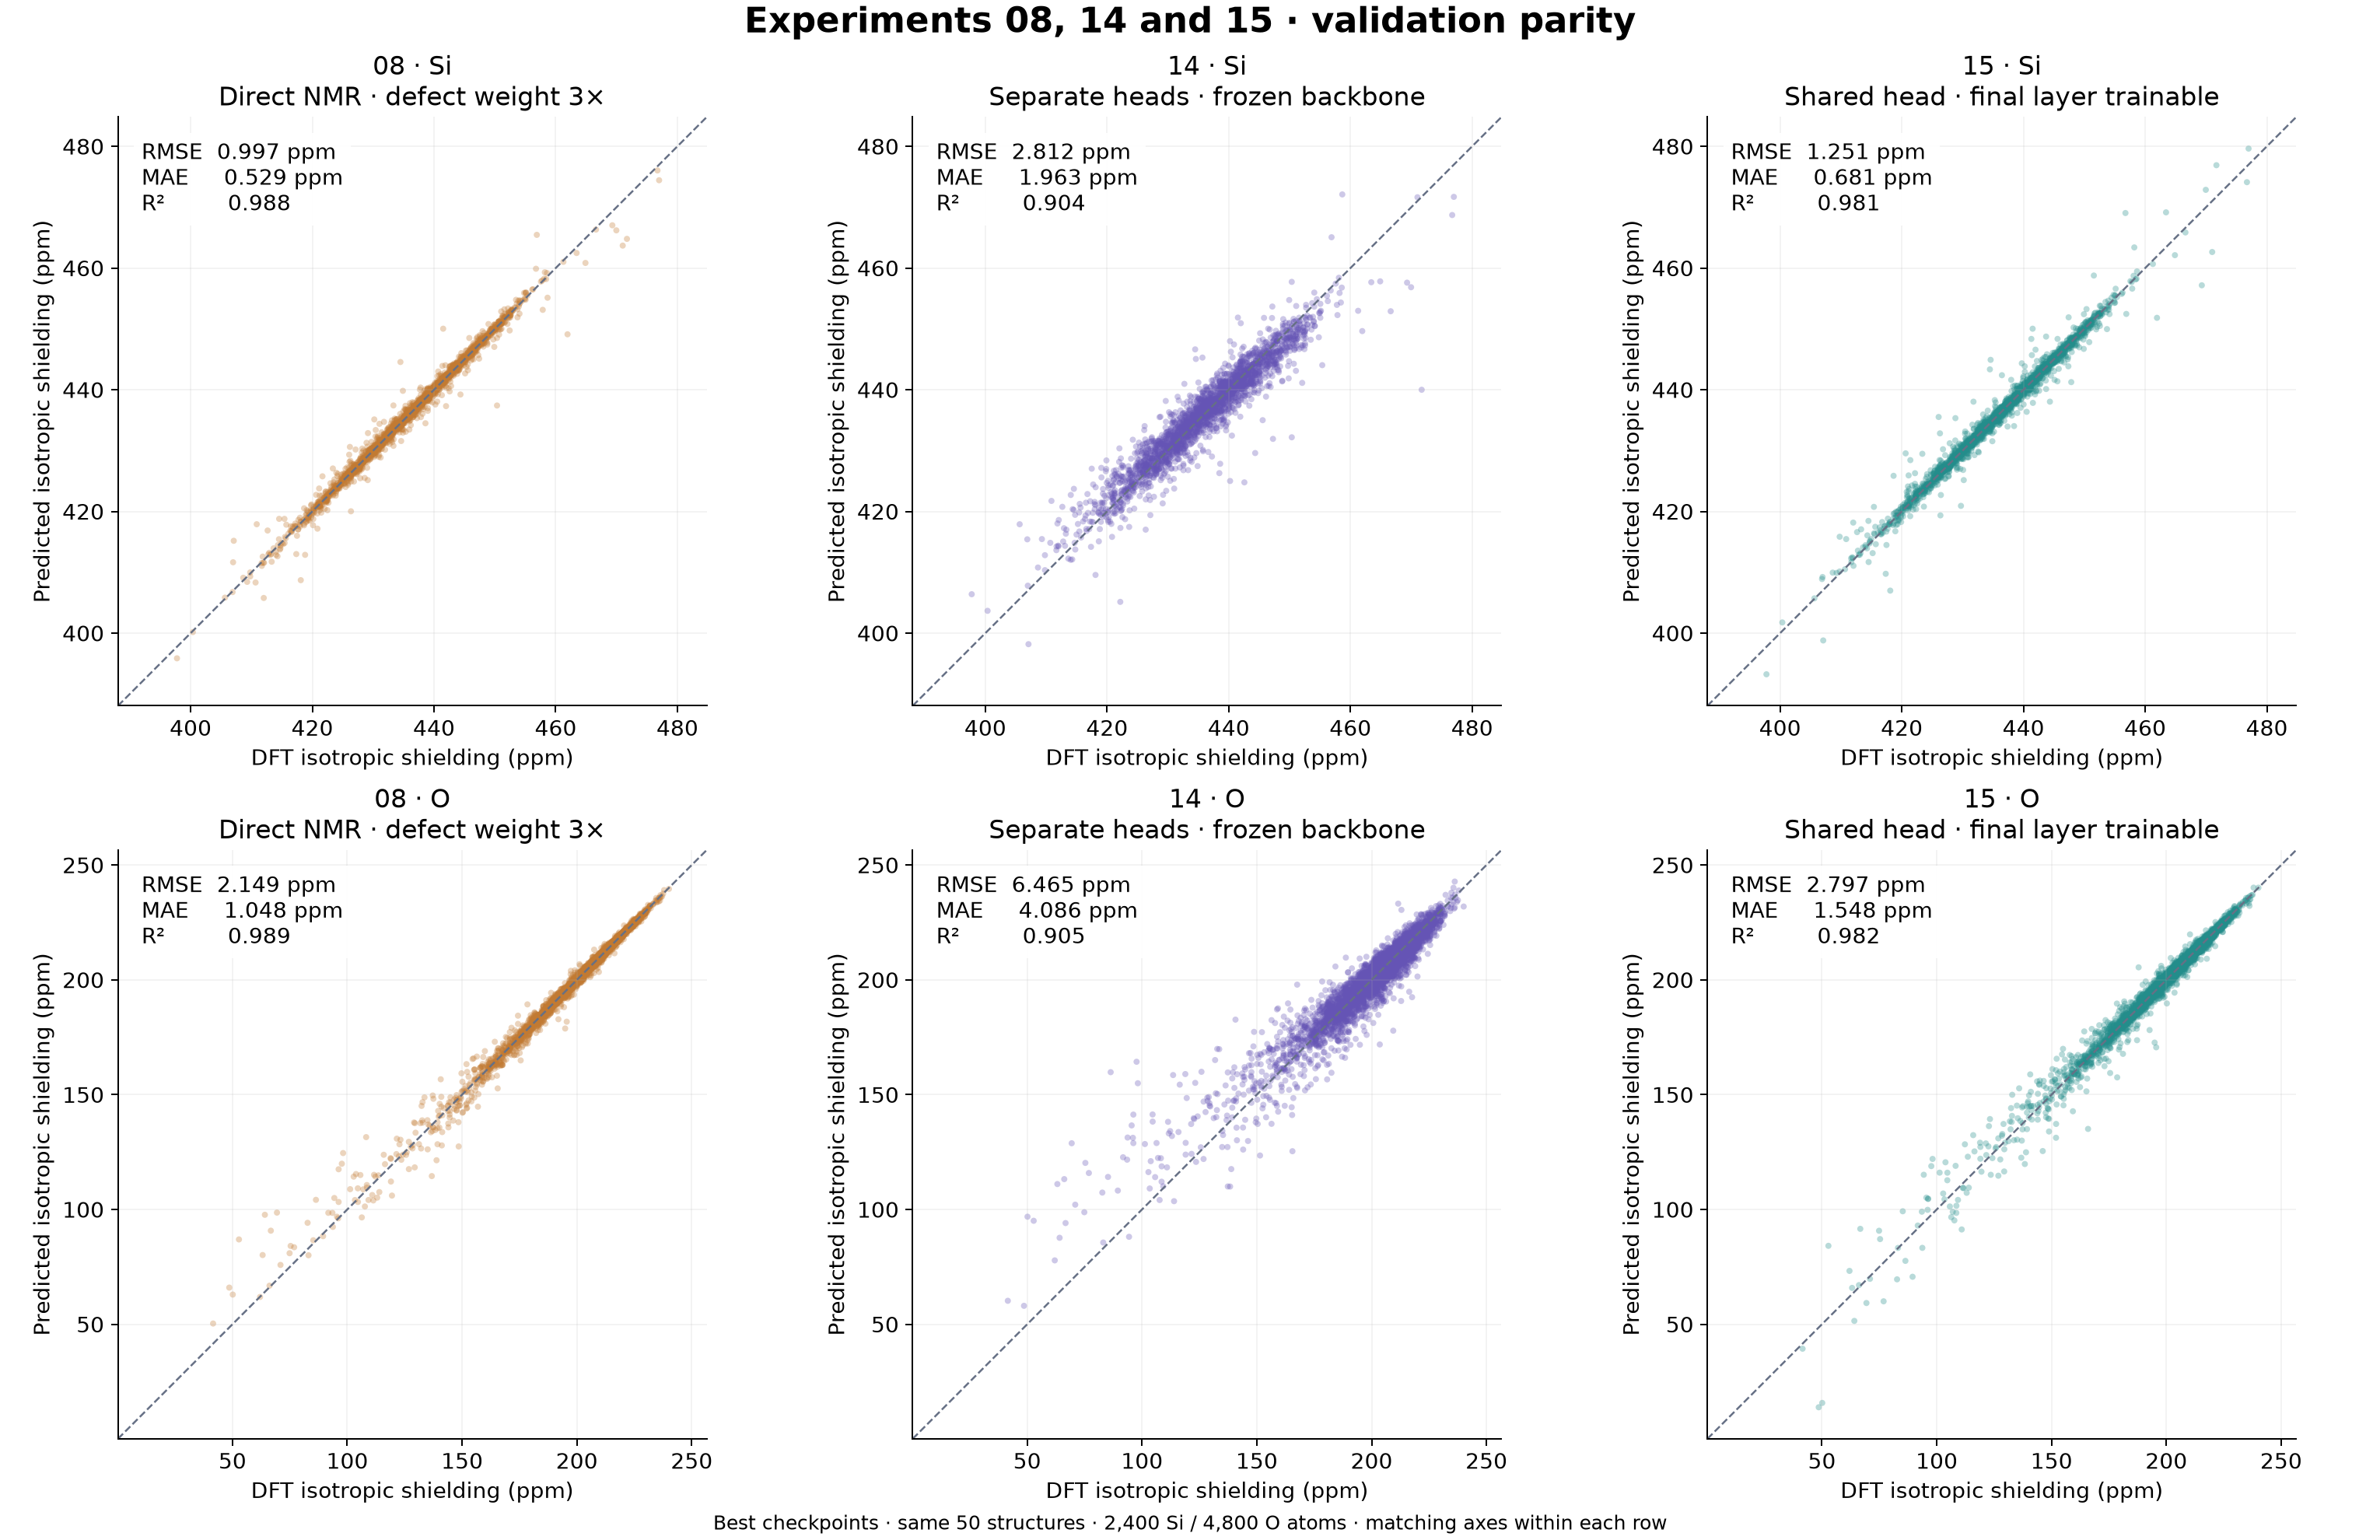

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

comparison_root = Path('/Users/louismcauliffe/code/research/NequIP_experiments/experiments')
comparison_name = '15-TensorNequIP-NMR-LastLayer-9148082'
comparison_out = Path(globals().get('COMPARISON_OUTPUT_DIR', comparison_root/(comparison_name+'-figures')))
comparison_out.mkdir(parents=True, exist_ok=True)
prior = pd.read_csv(comparison_root/'14-TensorNequIP-NMR-SeparateHeads-9136987-figures/predictions.csv.gz', dtype={'run':str})
prior = prior.query('run == "14" and checkpoint == "best"').copy()
current = pd.read_csv(comparison_root/(comparison_name+'-figures')/'predictions.csv.gz')
current['run'] = '15'
# Evaluate notebook 08's best direct-NMR checkpoint on the same validation set.
import sys, torch, json, hashlib
from ase.io import read
from graph_pes.atomic_graph import AtomicGraph
project = comparison_root.parent
sys.path.insert(0, str(project))
import nmr_helpers
run08 = project/'graph-pes-results/TensorNequIP-NMR-Coord3x-9083627'
torch.set_num_threads(4)
model08 = torch.load(run08/'model.pt', map_location='cpu', weights_only=False)
best08 = torch.load(run08/'checkpoints/best.ckpt', map_location='cpu', weights_only=False)
def states_equal(a,b):
    if isinstance(a,torch.Tensor): return isinstance(b,torch.Tensor) and torch.equal(a,b)
    if isinstance(a,dict): return a.keys()==b.keys() and all(states_equal(v,b[k]) for k,v in a.items())
    if isinstance(a,(list,tuple)): return type(a)==type(b) and len(a)==len(b) and all(states_equal(x,y) for x,y in zip(a,b))
    return a==b
assert states_equal(model08.state_dict(), {k.removeprefix('model.'):v for k,v in best08['state_dict'].items() if k.startswith('model.')})
model08.eval().requires_grad_(False)
valid_path = project/'data/nmr_iso/valid.xyz'
frames08 = read(valid_path,index=':')
rows08=[]
for i,atoms in enumerate(frames08):
    graph08 = AtomicGraph.from_ase(atoms,cutoff=float(model08.cutoff))
    assert not graph08.properties and not graph08.other
    with torch.no_grad():
        pred08 = model08.predict(graph08,['tensor'])['tensor'].cpu().numpy().copy()
    assert pred08.shape==(len(atoms),) and np.isfinite(pred08).all()
    rows08.append(pd.DataFrame(dict(structure=i,atom=np.arange(len(atoms)),element=atoms.get_chemical_symbols(),reference=np.asarray(atoms.arrays['MS_Iso_QM'],dtype=float),prediction=pred08,run='08')))
direct = pd.concat(rows08,ignore_index=True)
assert len(frames08)==50 and len(direct)==7200
direct.to_csv(comparison_out/'validation-predictions-08.csv.gz',index=False)
provenance08 = {'run':'TensorNequIP-NMR-Coord3x-9083627','best_epoch':int(best08['epoch'])+1,'description':'Direct NMR training, coordination-defect weight 3x; unweighted validation metrics','sha256':{str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in [valid_path,run08/'model.pt',run08/'checkpoints/best.ckpt']}}
(comparison_out/'comparison-08-14-15-provenance.json').write_text(json.dumps(provenance08,indent=2))
del model08,best08

# Check that both runs predict exactly the same reference sites.
keys = ['structure','atom','element']
a = prior.sort_values(keys).reset_index(drop=True)
b = current.sort_values(keys).reset_index(drop=True)
assert a[keys].equals(b[keys])
assert np.allclose(a.reference, b.reference, rtol=0, atol=1e-9)
d = direct.sort_values(keys).reset_index(drop=True)
assert d[keys].equals(b[keys])
assert np.allclose(d.reference,b.reference,rtol=0,atol=1e-9)
combined = pd.concat([direct, prior, current], ignore_index=True)
metric_rows=[]
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,
    'axes.spines.top':False,'axes.spines.right':False,'savefig.facecolor':'white'})
fig, axes = plt.subplots(2,3,figsize=(17,11),layout='constrained')
for row, element in enumerate(['Si','O']):
    all_sites = combined.query('element == @element')
    lo = min(all_sites.reference.min(), all_sites.prediction.min())
    hi = max(all_sites.reference.max(), all_sites.prediction.max())
    pad = .06*(hi-lo)
    limits = (lo-pad, hi+pad)
    for col, run in enumerate(['08','14','15']):
        ax = axes[row,col]
        g = all_sites.query('run == @run')
        y, p = g.reference.to_numpy(), g.prediction.to_numpy()
        rmse = np.sqrt(np.mean((p-y)**2))
        mae = np.mean(abs(p-y))
        r2 = 1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)
        metric_rows.append(dict(run=run,element=element,RMSE=rmse,MAE=mae,R2=r2))
        ax.scatter(y,p,s=10,alpha=.32,edgecolors='none',rasterized=True,
            color={'08':'#C27A32','14':'#6554B5','15':'#238D8B'}[run])
        ax.plot(limits,limits,'--',color='#667085',linewidth=1)
        description = {'08':'Direct NMR · defect weight 3×','14':'Separate heads · frozen backbone','15':'Shared head · final layer trainable'}[run]
        ax.set(xlim=limits,ylim=limits,aspect='equal',title=f'{run} · {element}\n{description}',
            xlabel='DFT isotropic shielding (ppm)',ylabel='Predicted isotropic shielding (ppm)')
        ax.text(.04,.96,f'RMSE  {rmse:.3f} ppm\nMAE     {mae:.3f} ppm\nR²         {r2:.3f}',
            transform=ax.transAxes,va='top',bbox=dict(facecolor='white',alpha=.95,edgecolor='none'))
        ax.grid(alpha=.15)
fig.suptitle('Experiments 08, 14 and 15 · validation parity',fontsize=18,weight='bold')
fig.supxlabel('Best checkpoints · same 50 structures · 2,400 Si / 4,800 O atoms · matching axes within each row',fontsize=10)
for ext in ['png','pdf']:
    fig.savefig(comparison_out/f'validation-parity-08-vs-14-vs-15.{ext}',dpi=180)
plt.close(fig)
display(Image(filename=str(comparison_out/'validation-parity-08-vs-14-vs-15.png')))

pd.DataFrame(metric_rows).to_csv(comparison_out/'comparison-08-14-15-metrics.csv',index=False)
